In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('penguins')

In [11]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

df_clean = df.dropna().reset_index(drop=True)

print(f"Дубликатов: {df_clean.duplicated().sum()}")

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_clean[col] = df_clean[col].clip(lower, upper)

(344, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
None
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Дубликатов: 0


In [12]:
print(df_clean.describe())

cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()
for col in cat_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count      333.000000     333.000000         333.000000   333.000000
mean        43.992793      17.164865         200.966967  4207.057057
std          5.468668       1.969235          14.015765   805.215802
min         32.100000      13.100000         172.000000  2700.000000
25%         39.500000      15.600000         190.000000  3550.000000
50%         44.500000      17.300000         197.000000  4050.000000
75%         48.600000      18.700000         213.000000  4775.000000
max         59.600000      21.500000         231.000000  6300.000000

species:
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

island:
island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64

sex:
sex
Male      168
Female    165
Name: count, dtype: int64


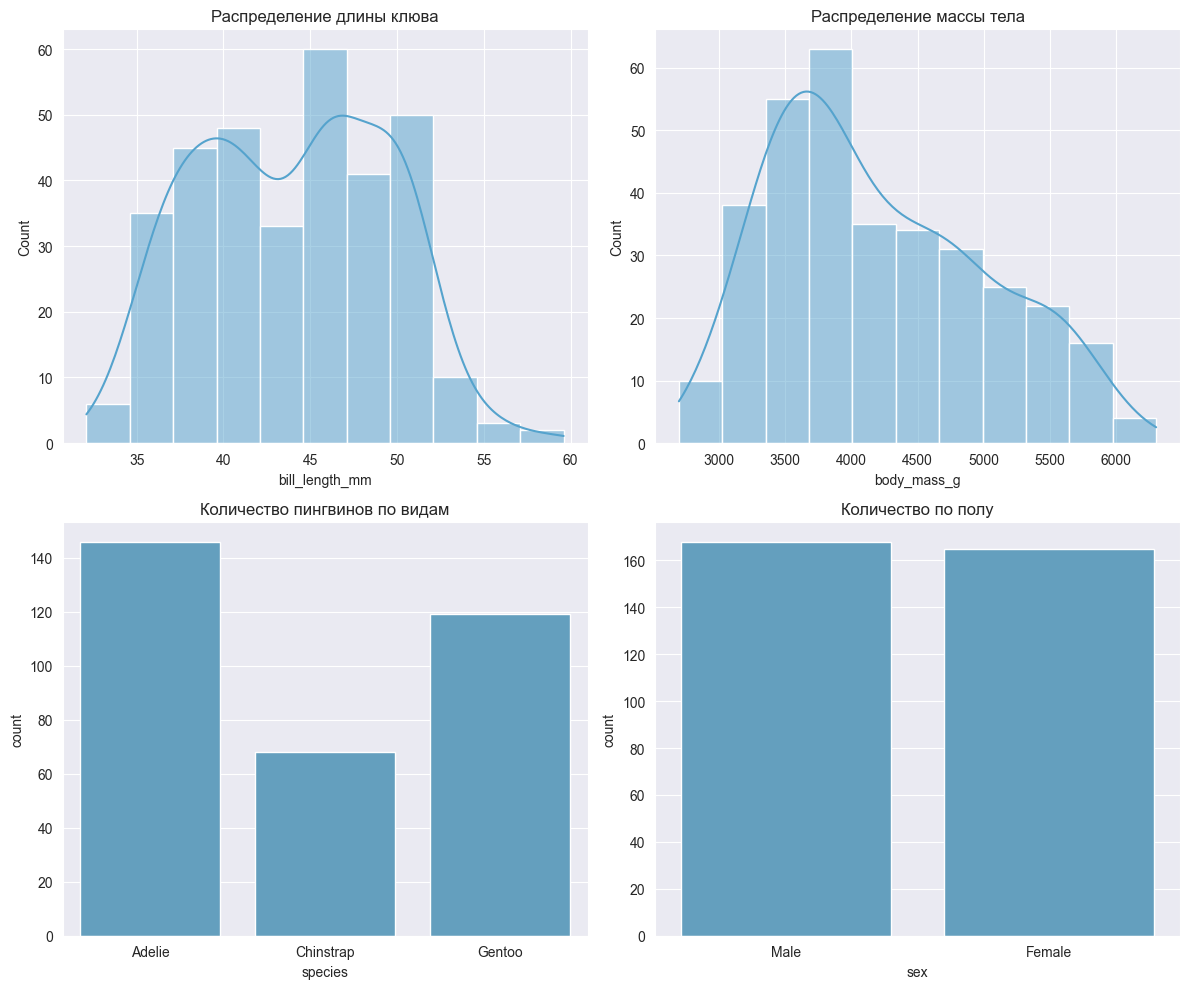

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(data=df_clean, x='bill_length_mm', kde=True, ax=axes[0,0])
axes[0,0].set_title('Распределение длины клюва')

sns.histplot(data=df_clean, x='body_mass_g', kde=True, ax=axes[0,1])
axes[0,1].set_title('Распределение массы тела')

sns.countplot(data=df_clean, x='species', ax=axes[1,0])
axes[1,0].set_title('Количество пингвинов по видам')

sns.countplot(data=df_clean, x='sex', ax=axes[1,1])
axes[1,1].set_title('Количество по полу')

plt.tight_layout()
plt.show()

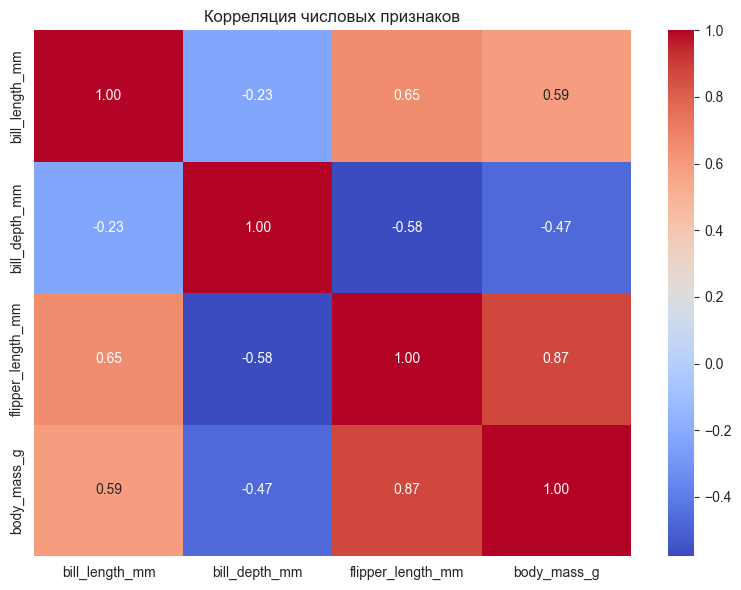

In [14]:
plt.figure(figsize=(8, 6))
corr = df_clean[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляция числовых признаков')
plt.tight_layout()
plt.show()

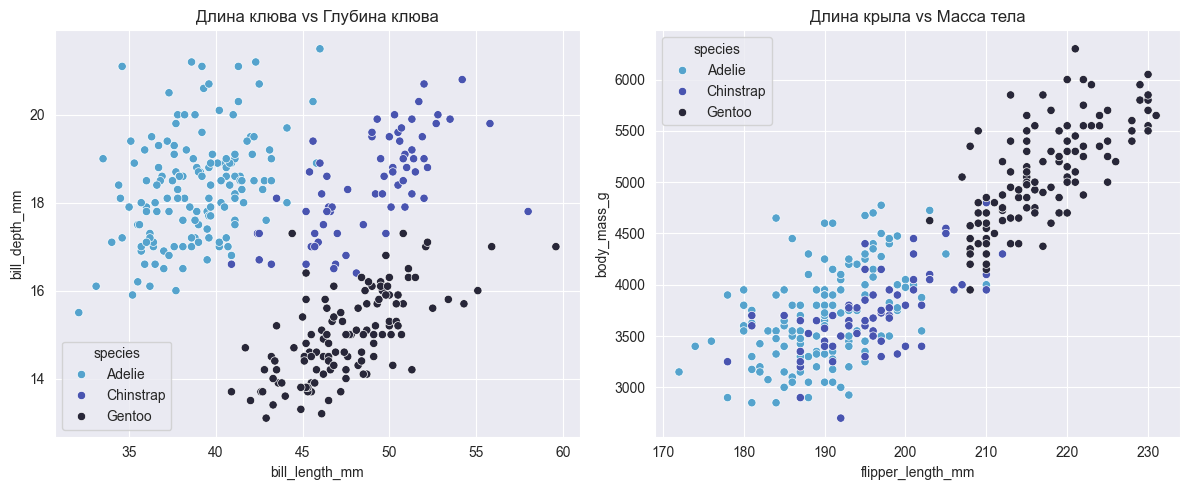

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df_clean, x='bill_length_mm', y='bill_depth_mm', hue='species', ax=axes[0])
axes[0].set_title('Длина клюва vs Глубина клюва')

sns.scatterplot(data=df_clean, x='flipper_length_mm', y='body_mass_g', hue='species', ax=axes[1])
axes[1].set_title('Длина крыла vs Масса тела')

plt.tight_layout()
plt.show()

In [16]:
print("\nСредние показатели по видам пингвинов:")
print(df_clean.groupby('species')[numeric_cols].mean().round(2))

print("\nМедианные показатели по полу:")
print(df_clean.groupby('sex')[numeric_cols].median().round(2))

print("\nСредняя масса тела по островам:")
print(df_clean.groupby('island')['body_mass_g'].mean().round(2))


Средние показатели по видам пингвинов:
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie              38.82          18.35             190.10      3706.16
Chinstrap           48.83          18.42             195.82      3733.09
Gentoo              47.57          15.00             217.24      5092.44

Медианные показатели по полу:
        bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
sex                                                                  
Female            42.8          17.00              193.0       3650.0
Male              46.8          18.45              200.5       4300.0

Средняя масса тела по островам:
island
Biscoe       4719.17
Dream        3718.90
Torgersen    3708.51
Name: body_mass_g, dtype: float64


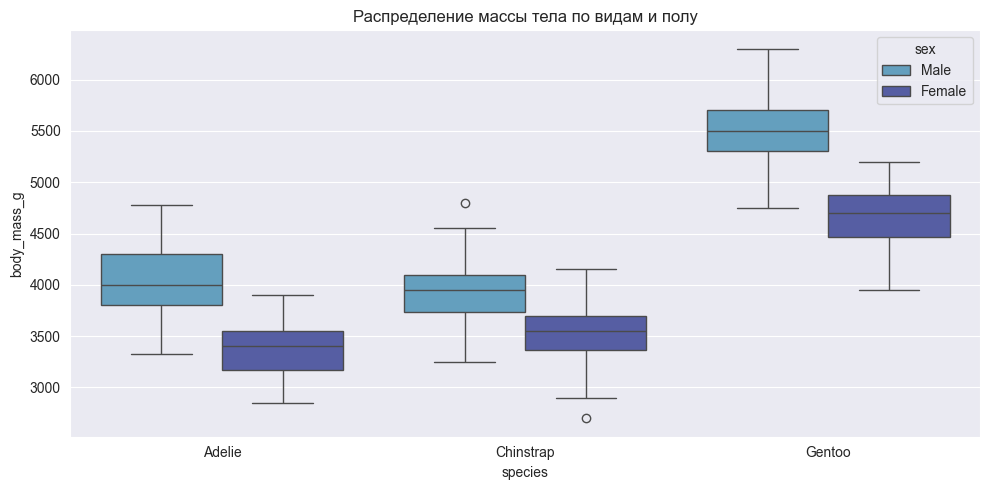

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x='species', y='body_mass_g', hue='sex')
plt.title('Распределение массы тела по видам и полу')
plt.tight_layout()
plt.show()

ПыСы: ладно, убедили, я понял прикол разъячеивания - в божественной Intelij Idea это отлично позволяет оценивать контекстные значения переменных без лишней кучи принтов - сок